In [2]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys

sys.path.insert(0, str(Path("../src").resolve()))
from data_io import load_assembled

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.colors import to_hex

from trompy import save_figure_atomic

from figure_config import (
    configure_matplotlib, COLORS, HEATMAP_CMAP_DIV,
    DATAFOLDER, RESULTSFOLDER, FIGSFOLDER,
    SAVE_FIGS
)

# from utils import make_realigned_trials
from realignment_helpers import get_realigned_data

SAVE_FIGS = True

# Configure matplotlib
configure_matplotlib()
colors = COLORS  # Use shared color palette
custom_cmap = HEATMAP_CMAP_DIV  # Use shared colormap

# 11 evenly spaced colors from custom_cmap
sampled_hex = [to_hex(custom_cmap(x)) for x in np.linspace(0, 1, 11)]
DA_COLOR = sampled_hex[0]  # Choose the 3rd color for DA
BEHAV_COLOR = sampled_hex[-1]  # Choose the 6th color for behavior

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
assembled_data_path = DATAFOLDER / "assembled"

data = load_assembled(assembled_data_path)

# Extract main components
x_array = data["x_array"].copy()

# reverses cluster assignments
x_array["cluster_photo"] = x_array["cluster_photo"].map({0: 1, 1: 0})

print(f"Loaded assembled data from {assembled_data_path}")
print(f"\nData structure:")
print(f"  - x_array shape: {x_array.shape}")

Loaded assembled data from C:\Users\jmc010\Github\bazzino\data\assembled_data.pickle

Data structure:
  - x_array shape: (1960, 30)


In [4]:
# additional analysis for revision

da_transition = []
behav_transition = []
for rat in x_array.id.unique():

    rat_data = (x_array
    .query("condition == 'deplete' and infusiontype == '45NaCl' and id == @rat and realigned_trials_da_velocity == 0")
    .rename(columns={"trial": "da_transition"})
    )
    if len(rat_data) > 0:
        da_transition.append(rat_data.loc[:, ["id", "sex", "da_transition"]])

    rat_data = (x_array
    .query("condition == 'deplete' and infusiontype == '45NaCl' and id == @rat and realigned_trials_behav == 0")
    .rename(columns={"trial": "behav_transition"})
    )
    if len(rat_data) > 0:
        behav_transition.append(rat_data.loc[:, ["id", "sex", "behav_transition"]])

da_transition = pd.concat(da_transition).reset_index(drop=True)
behav_transition = pd.concat(behav_transition).reset_index(drop=True)

df_transition = pd.merge(left=da_transition, right=behav_transition)
df_transition["bodyweight"] = [247, 237, 266, 470, 332, 304, 454, 540, 281, 278]

In [5]:
df_transition

,id,sex,da_transition,behav_transition,bodyweight
0,PB26,M,23,29,247
1,PB27,M,29,47,237
2,PB30,F,15,28,266
3,PB31,M,18,17,470
4,PB46,F,4,9,332
5,PB48,F,23,24,304
6,PB71,M,15,22,454
7,PB72,M,9,13,540
8,PB73,F,18,21,281
9,PB75,F,31,31,278


[-0.03458372]
[0.02400497]
[-0.0236685]
[0.00337394]
[-0.0485425]
[0.0418747]
[0.04007149]
[-0.04665786]
[0.04569493]
[-0.03627907]


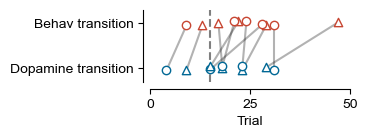

In [6]:

f, ax = plt.subplots(figsize=(4, 1.5),
                     gridspec_kw={"left": 0.4, "bottom": 0.4},)

np.random.seed(12)
for _, row in df_transition.iterrows():
    if row.sex == "M":
        marker = "^"
    elif row.sex == "F":
        marker = "o"

    
    jitter = np.random.random(1) * 0.1 - 0.05
    print(jitter)

    ax.scatter(row.da_transition, 1+jitter[0],
               marker=marker,
               facecolors="w", edgecolors=DA_COLOR)
    ax.scatter(row.behav_transition, 2+jitter[0],
               marker=marker,
               facecolors="w", edgecolors=BEHAV_COLOR)

    ax.plot((row.da_transition, row.behav_transition),
            (1+jitter[0], 2+jitter[0]),
            color="k", alpha=0.3,
            zorder=-10)


ax.axvline(15, linestyle="--", alpha=0.5, zorder=-20, color="k")

ax.set_yticks([1,2], labels=["Dopamine transition", "Behav transition"])
ax.set_xlabel("Trial")
ax.set_ylim(0.7, 2.3)
ax.set_xticks([0,25,50])
sns.despine(offset=5)

save_figure_atomic(f, "figSx_da_and_behav_transitions", FIGSFOLDER)



In [ ]:
# stats to test whether transition points differ by sex

from scipy import stats

for variable in ["behav_transition", "da_transition"]:
    female = df_transition.loc[
        df_transition["sex"] == "F", variable
    ].dropna()

    male = df_transition.loc[
        df_transition["sex"] == "M", variable
    ].dropna()

    # Welch's independent-samples t-test
    t_stat, t_p = stats.ttest_ind(
        female,
        male,
        equal_var=False,
    )

    # Mann-Whitney U test
    u_stat, u_p = stats.mannwhitneyu(
        female,
        male,
        alternative="two-sided",
    )

    print(f"\n{variable}")
    print(f"F: n={len(female)}, mean={female.mean():.2f}, SD={female.std():.2f}")
    print(f"M: n={len(male)}, mean={male.mean():.2f}, SD={male.std():.2f}")
    print(f"Welch t-test: t={t_stat:.2f}, p={t_p:.3f}")
    print(f"Mann-Whitney U: U={u_stat:.2f}, p={u_p:.3f}")

In [ ]:
# plot with body weight
f, [ax1, ax2] = plt.subplots(figsize=(3, 1.5), ncols=2, sharey=True,
                             gridspec_kw={"left": 0.3, "bottom": 0.4, "wspace": 0.3})

for _, row in df_transition.iterrows():
    if row.sex == "M":
        marker = "^"
    elif row.sex == "F":
        marker = "o"

    ax1.scatter(row.behav_transition, row.bodyweight,
            marker=marker,
            facecolors="w", edgecolors=BEHAV_COLOR,
            clip_on=False)
    
    ax2.scatter(row.da_transition, row.bodyweight,
               marker=marker,
               facecolors="w", edgecolors=DA_COLOR,
               clip_on=False)


sns.regplot(
    data=df_transition,
    x="behav_transition",
    y="bodyweight",
    ax=ax1,
    scatter=False,
    ci=None,
    color=BEHAV_COLOR,
    line_kws={"linewidth": 1, "linestyle": "--"},
)

sns.regplot(
    data=df_transition,
    x="da_transition",
    y="bodyweight",
    ax=ax2,
    scatter=False,
    ci=None,
    color=DA_COLOR,
    line_kws={"linewidth": 1, "linestyle": "--"},
)

ax1.set_xlabel("Behav transition")
ax2.set_xlabel("DA transition")

ax1.set_ylabel("Body weight (g)")
ax2.set_ylabel("")

for axis in [ax1, ax2]:
    sns.despine(ax=axis, offset=5)
    axis.set_xlim(0, 50)

save_figure_atomic(f, "figSx_transitions_vs_bodyweight", FIGSFOLDER)



In [ ]:
import statsmodels.formula.api as smf

model = smf.ols(
    "behav_transition ~ bodyweight",
    data=df_transition
).fit()

print(model.summary())

In [ ]:
model = smf.ols(
    "da_transition ~ bodyweight",
    data=df_transition
).fit()

print(model.summary())

In [ ]:
model = smf.ols(
    "behav_transition ~ bodyweight + C(sex)",
    data=df_transition
).fit()

print(model.summary())